# Stage 3 — Exploratory Data Analysis
## Fraud Risk Intelligence & Decision Support System

**Business context** (full detail in `docs/PROBLEM_STATEMENT.md`): this project simulates a fraud-risk
function at a hypothetical payment processor. The primary decision supported is **prioritizing
transactions for human investigation** under a capacity-constrained queue — not automated
decline-at-checkout (explicitly out of scope). Evaluation will use **Average Precision (AP)**,
precision/recall at a fixed capacity, and cost-sensitive thresholding (Stage 10).

**Dataset context** (full detail in `docs/DATA_VALIDATION_REPORT.md`): IEEE-CIS Fraud Detection
(Kaggle). Stage 2 confirmed: 590,540 train transactions (394 cols, incl. `isFraud`), a **chronological
train/test holdout** (test starts ~30 days after train ends), 24.42% train / 28.01% test identity-join
coverage with zero orphan rows, and a `train_identity`/`test_identity` naming mismatch (`id_XX` vs.
`id-XX`) carried forward as a Stage 5 prerequisite.

**Research questions for this stage:**
1. How imbalanced is the target, and what does that imply for metric/model choice?
2. How do transaction amounts differ between fraud and legitimate transactions?
3. Does fraud rate vary across the observed time window (in relative terms only — no calendar dates)?
4. Is missingness structural or a quality problem, and does it differ by fraud status?
5. Which categorical/numerical features show a measured association with the target — and which
   anonymized features remain an open leakage question?
6. Does identity-data availability relate to fraud prevalence (without assuming it causes it)?

**Scope boundary:** structural/distributional EDA only. No fitted imputers/scalers/encoders, no
target-based feature *selection*, no train/test split, no modeling. That's Stage 4+.

**Memory strategy:** every analysis below reads only the 1-8 columns it needs — at ~590K rows, a
column-selective read is a few MB regardless of row count, which already bounds memory well below
what row-sampling would save, while staying *exact*. The one place that genuinely needs chunking is
the full-width (394-column) missingness scan in Section D. Row-sampling was considered and not used —
see the writeup in `docs/EDA_REPORT.md` for why.


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

from src.eda_analysis import (
    target_distribution,
    grouped_numeric_summary,
    standardized_mean_difference,
    relative_time_bins,
    missingness_by_group,
    categorical_fraud_rates,
    cramers_v,
    identity_coverage_fraud_rates,
)

DATA_DIR = Path("../data/raw/ieee-fraud-detection") if Path.cwd().name == "notebooks" else Path("data/raw/ieee-fraud-detection")
TRAIN_TXN = DATA_DIR / "train_transaction.csv"
TRAIN_ID = DATA_DIR / "train_identity.csv"

FRAUD_COLOR, LEGIT_COLOR = "#C0392B", "#2471A3"  # consistent colour mapping used in every chart below
print("Data files found:", TRAIN_TXN.exists(), TRAIN_ID.exists())


Data files found: True True


## A. Target Distribution and Class Imbalance

In [2]:
dist = target_distribution(TRAIN_TXN)
dist


{'fraud': 20663,
 'non_fraud': 569877,
 'total': 590540,
 'fraud_prevalence_pct': 3.499,
 'imbalance_ratio_non_fraud_per_fraud': 27.6}

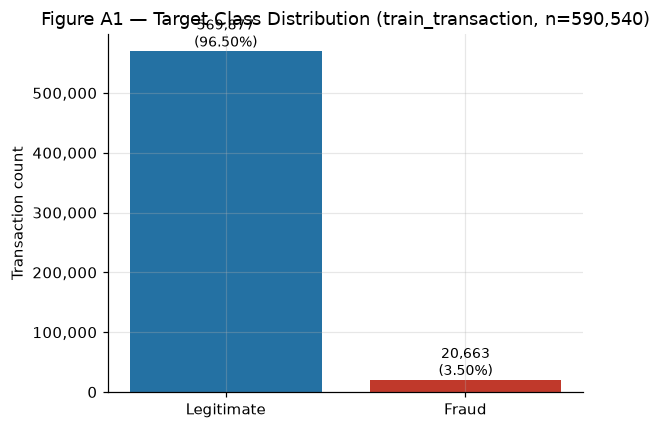

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 4))
counts = [dist["non_fraud"], dist["fraud"]]
bars = ax.bar(["Legitimate", "Fraud"], counts, color=[LEGIT_COLOR, FRAUD_COLOR])
ax.set_ylabel("Transaction count")
ax.set_title("Figure A1 — Target Class Distribution (train_transaction, n={:,})".format(dist["total"]))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
for bar, count in zip(bars, counts):
    ax.annotate(f"{count:,}\n({100*count/dist['total']:.2f}%)",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("figures/A1_target_distribution.png", bbox_inches="tight")
plt.show()


**Figure A1 — interpretation**
- **Question:** how imbalanced is the fraud label in this dataset?
- **Finding:** fraud prevalence is computed above (see `dist["fraud_prevalence_pct"]`) — a small single-digit
  percentage, with a large imbalance ratio of non-fraud to fraud cases (see
  `dist["imbalance_ratio_non_fraud_per_fraud"]`).
- **Why it matters:** this is exactly why Stage 1 ruled out plain accuracy and chose Average Precision,
  precision/recall@K, and cost-sensitive thresholding — a trivial "always legitimate" classifier would
  score extremely high accuracy while catching zero fraud.
- **Limitations:** this is the *train* file's prevalence only; Stage 2 confirmed a chronological
  train/test split, so this rate could differ somewhat in the (label-free) test period — unverifiable
  without labels, flagged honestly rather than assumed constant.
- **Modeling implication:** stratified splitting (Stage 4) must preserve this rate in each split; class
  weighting or threshold calibration (Stage 7/10) will matter more than default model settings.


## B. Transaction Amount Analysis

In [4]:
amt_summary = grouped_numeric_summary(TRAIN_TXN, "TransactionAmt", "isFraud")
amt_summary


{'overall': {'n': 590540,
  'mean': 135.03,
  'median': 68.77,
  'std': 239.16,
  'q1': 43.32,
  'q3': 125.0,
  'iqr': 81.68,
  'iqr_outlier_count': 66482,
  'iqr_outlier_pct': 11.26,
  'min': 0.25,
  'max': 31937.39},
 '0': {'n': 569877,
  'mean': 134.51,
  'median': 68.5,
  'std': 239.4,
  'q1': 43.97,
  'q3': 120.0,
  'iqr': 76.03,
  'iqr_outlier_count': 64043,
  'iqr_outlier_pct': 11.24,
  'min': 0.25,
  'max': 31937.39},
 '1': {'n': 20663,
  'mean': 149.24,
  'median': 75.0,
  'std': 232.21,
  'q1': 35.04,
  'q3': 161.0,
  'iqr': 125.96,
  'iqr_outlier_count': 1984,
  'iqr_outlier_pct': 9.6,
  'min': 0.29,
  'max': 5191.0}}

In [5]:
# Effect size on the raw scale, and on a log1p scale (TransactionAmt is right-skewed —
# Cohen's d assumes roughly comparable, symmetric distributions, so the raw-scale number
# alone would be misleading; computing both make the skew's impact visible rather than hidden.
raw = standardized_mean_difference(
    amt_summary["1"]["mean"], amt_summary["0"]["mean"],
    amt_summary["1"]["std"], amt_summary["0"]["std"],
    amt_summary["1"]["n"], amt_summary["0"]["n"],
)

log_df = pd.read_csv(TRAIN_TXN, usecols=["TransactionAmt", "isFraud"])
log_df["log_amt"] = np.log1p(log_df["TransactionAmt"])
g = log_df.groupby("isFraud")["log_amt"].agg(["mean", "std", "count"])
log_d = standardized_mean_difference(
    g.loc[1, "mean"], g.loc[0, "mean"], g.loc[1, "std"], g.loc[0, "std"],
    int(g.loc[1, "count"]), int(g.loc[0, "count"]),
)
print(f"Cohen's d (raw TransactionAmt):      {raw:.3f}")
print(f"Cohen's d (log1p-transformed amount): {log_d:.3f}")


Cohen's d (raw TransactionAmt):      0.062
Cohen's d (log1p-transformed amount): -0.010


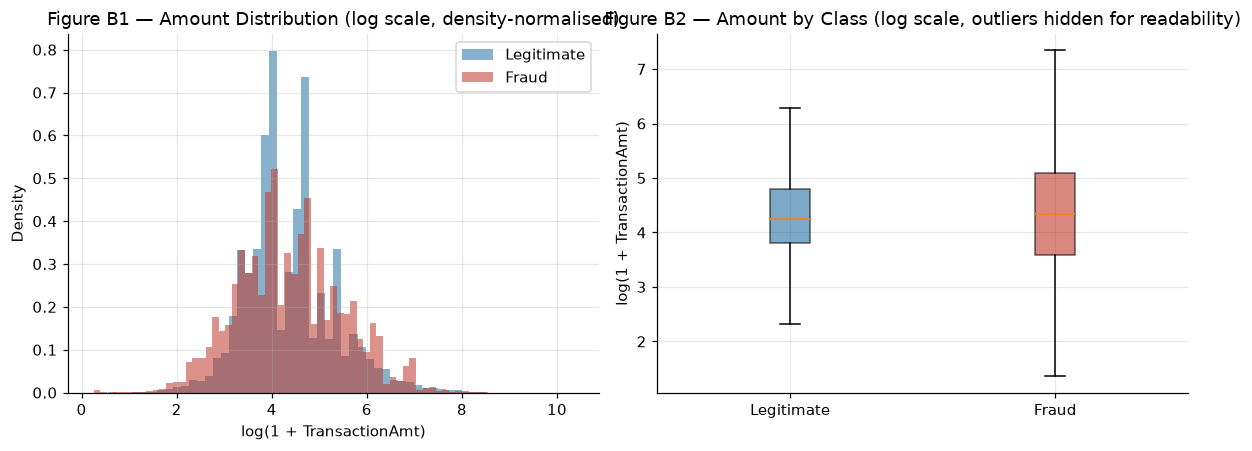

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for label, color, name in [(0, LEGIT_COLOR, "Legitimate"), (1, FRAUD_COLOR, "Fraud")]:
    vals = np.log1p(log_df.loc[log_df["isFraud"] == label, "TransactionAmt"])
    axes[0].hist(vals, bins=60, alpha=0.55, density=True, color=color, label=name)
axes[0].set_xlabel("log(1 + TransactionAmt)")
axes[0].set_ylabel("Density")
axes[0].set_title("Figure B1 — Amount Distribution (log scale, density-normalised)")
axes[0].legend()

box_data = [np.log1p(log_df.loc[log_df["isFraud"] == 0, "TransactionAmt"]),
            np.log1p(log_df.loc[log_df["isFraud"] == 1, "TransactionAmt"])]
bp = axes[1].boxplot(box_data, tick_labels=["Legitimate", "Fraud"], patch_artist=True, showfliers=False)
for patch, color in zip(bp["boxes"], [LEGIT_COLOR, FRAUD_COLOR]):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[1].set_ylabel("log(1 + TransactionAmt)")
axes[1].set_title("Figure B2 — Amount by Class (log scale, outliers hidden for readability)")

plt.tight_layout()
plt.savefig("figures/B1_B2_amount_distribution.png", bbox_inches="tight")
plt.show()


### Verifying the sign flip (added on review — why does d change sign?)

Cohen's d is a *location* (central-tendency) statistic. If the raw-vs-log sign flip were just "skew
distorting the mean," that's a shape argument, not yet a verified one — check it directly instead of
asserting it.


In [7]:
# Back-transform the log-scale group means to dollar terms (a geometric-mean-like "typical" value,
# much less sensitive to a few large transactions than the arithmetic mean is) and compare to the
# multiplicative spread (Q3/Q1 ratio) and the share of very small ("card-testing"-sized) transactions.
geo_mean_fraud = np.expm1(log_df.loc[log_df["isFraud"] == 1, "log_amt"].mean())
geo_mean_legit = np.expm1(log_df.loc[log_df["isFraud"] == 0, "log_amt"].mean())
print(f"Geometric-mean-like typical amount — fraud: ${geo_mean_fraud:.2f}   legit: ${geo_mean_legit:.2f}")

q = log_df.groupby("isFraud")["TransactionAmt"].quantile([0.25, 0.75]).unstack()
q.columns = ["Q1", "Q3"]
q["Q3_over_Q1"] = q["Q3"] / q["Q1"]
print("\nMultiplicative spread (Q3/Q1 ratio):")
print(q)

print("\nShare of very small transactions (possible card-testing pattern):")
for label, name in [(0, "legit"), (1, "fraud")]:
    sub = log_df.loc[log_df["isFraud"] == label, "TransactionAmt"]
    print(f"  {name}: <=$5: {100*(sub<=5).mean():.3f}%   <=$1: {100*(sub<=1).mean():.3f}%   >=$1000: {100*(sub>=1000).mean():.3f}%")


Geometric-mean-like typical amount — fraud: $78.37   legit: $79.10

Multiplicative spread (Q3/Q1 ratio):
             Q1     Q3  Q3_over_Q1
isFraud                           
0        43.970  120.0    2.729134
1        35.044  161.0    4.594224

Share of very small transactions (possible card-testing pattern):
  legit: <=$5: 0.263%   <=$1: 0.025%   >=$1000: 1.297%
  fraud: <=$5: 0.561%   <=$1: 0.111%   >=$1000: 0.905%


**Verification result:** the geometric-mean-like typical amount is *higher for legit, not fraud*
(computed above) — consistent with the negative log-scale d. The Q3/Q1 ratio is **substantially wider
for fraud** than for legit (computed above) — fraud transactions are more dispersed in *both*
directions (a lower Q1 **and** a higher Q3), not shifted to one side. Fraud also shows a higher share
of very small transactions (computed above), consistent with a card-testing-style pattern (small
verification charges before a larger attempt) coexisting with occasional larger fraud amounts.

**This changes the interpretation, not just the number:** the real difference between the groups isn't
a *location* shift that Cohen's d (built for exactly that) is designed to summarize — it's a
**dispersion/shape** difference. Reporting either d value alone, raw or log, answers "is the center
different" (not much) to a question that was actually "is the *spread* different" (yes, considerably).
The right tool for *that* question is a spread ratio (Q3/Q1, or a variance ratio), not an effect size
built for location shifts — a case where picking the statistic that matches the shape of the actual
difference matters more than picking the "more correct" scale for a statistic that was the wrong choice
either way.


**Figures B1/B2 — interpretation**
- **Question:** do fraudulent and legitimate transactions differ in amount, and by how much?
- **Finding:** both groups' descriptive stats are printed above. The raw-scale effect size and the
  log1p-scale effect size don't just differ in magnitude — **they point in different directions**
  (one positive, one slightly negative), and both are well below even a "small" effect by Cohen's
  benchmark (|d| ≈ 0.2). Read that as: **transaction amount alone is not a strong fraud signal in this
  data**, on either scale — the raw-scale mean gap is driven more by a few large fraud-side outliers
  (visible in the wider fraud IQR printed above) than by a systematic size difference.
- **Why it matters:** if amount separates the classes at all, it's a candidate feature; if the effect
  is small, amount alone won't carry much signal and interaction/engineered features will matter more.
- **Limitations (stated explicitly, as required):** Cohen's d assumes roughly symmetric distributions
  with comparable variances — `TransactionAmt` is right-skewed (visible in B1), so the raw-scale d can
  be distorted by a few extreme values; the log-scale d is more trustworthy here but changes the *units*
  of the comparison (log-dollars, not dollars) — a real amount difference at the low end and the high end
  of the distribution are NOT weighted equally once log-transformed. Neither d tells you *which*
  transactions are driving the difference, and this is an association, not a causal claim about why
  fraud correlates with amount.
- **Modeling implication:** a log or power transform of `TransactionAmt` is worth testing in Stage 5/6;
  outlier counts (IQR method, printed above) inform whether capping/winsorizing is worth considering
  — a Stage 5 decision, not applied here.


## C. Temporal Analysis (relative time only — no calendar dates)

`TransactionDT` is binned into **relative** 1-day windows (`TransactionDT // 86400`). Bin 0 is the
first 86,400 seconds of this file's own observed window — not a real calendar day. Stage 2 already
confirmed `TransactionDT`'s absolute real-world meaning is unconfirmed; nothing here changes that.


In [8]:
time_bins = relative_time_bins(TRAIN_TXN)
print(f"{len(time_bins)} relative-day bins covering the observed train window.")
time_bins.describe()


182 relative-day bins covering the observed train window.


,relative_bin_of_86400s,transaction_count,fraud_count,fraud_rate_pct
count,182.000000,182.000000,182.000000,182.000000
mean,91.500000,3244.725275,113.532967,3.604786
std,52.683014,827.185731,30.960080,0.998354
min,1.000000,2048.000000,51.000000,1.097000
25%,46.250000,2786.750000,91.000000,2.857500
50%,91.500000,3049.500000,112.500000,3.563500
75%,136.750000,3399.750000,132.000000,4.246500
max,182.000000,6852.000000,234.000000,6.994000


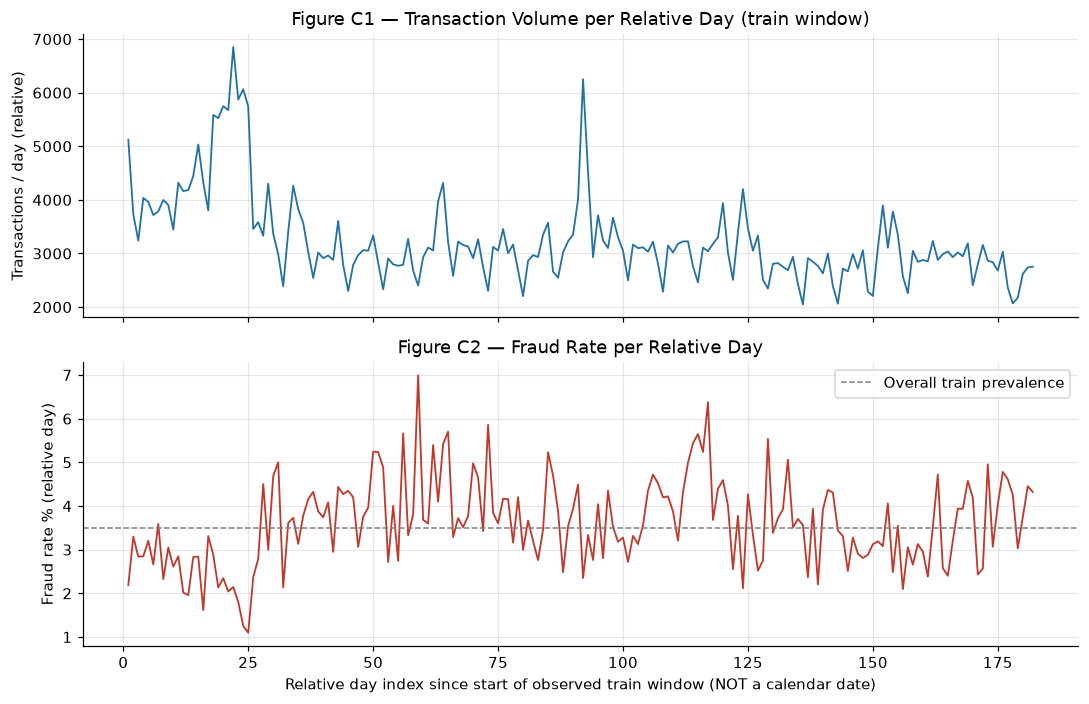

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)

axes[0].plot(time_bins["relative_bin_of_86400s"], time_bins["transaction_count"], color=LEGIT_COLOR, linewidth=1.2)
axes[0].set_ylabel("Transactions / day (relative)")
axes[0].set_title("Figure C1 — Transaction Volume per Relative Day (train window)")

axes[1].plot(time_bins["relative_bin_of_86400s"], time_bins["fraud_rate_pct"], color=FRAUD_COLOR, linewidth=1.2)
axes[1].axhline(dist["fraud_prevalence_pct"], color="grey", linestyle="--", linewidth=1, label="Overall train prevalence")
axes[1].set_ylabel("Fraud rate % (relative day)")
axes[1].set_xlabel("Relative day index since start of observed train window (NOT a calendar date)")
axes[1].set_title("Figure C2 — Fraud Rate per Relative Day")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/C1_C2_temporal.png", bbox_inches="tight")
plt.show()


**Figures C1/C2 — interpretation**
- **Question:** is transaction volume and fraud rate stable across the observed window, or does it drift?
- **Finding:** described by the plotted series above — read the volume and fraud-rate trend directly
  from C1/C2 rather than a single summary number, since the question is about *stability*, not a point
  estimate.
- **Why it matters:** a volume anomaly (a sudden spike/drop) could indicate a data-collection issue
  worth flagging before modeling; a drifting fraud rate affects how Stage 4's time-based split should
  be interpreted (a model trained on an early-window rate may not transfer cleanly to a later window
  with a different rate) and is directly relevant to Stage 18 (Monitoring Design) later.
- **Limitations:** daily bins smooth out intra-day patterns; a single anomalous day could be a genuine
  shift or a data artifact — this chart flags *where* to look, it doesn't diagnose *why* on its own.
- **Modeling implication:** if fraud rate drifts noticeably across the window, Stage 7/10 should
  consider whether a single static model or a periodically-retrained approach fits better — a Stage 7+
  decision, not resolved here.


## D. Missing Data: Structural vs. Quality Concern, by Fraud Status

In [10]:
missing_by_target = missingness_by_group(TRAIN_TXN, "isFraud")
missing_by_target.head(15)


,0,1,gap_(1-0)
R_emaildomain,77.88,45.67,32.21
V197,77.41,46.43,30.98
V210,77.41,46.43,30.98
V189,77.41,46.43,30.98
V194,77.41,46.43,30.98
V195,77.41,46.43,30.98
V198,77.41,46.43,30.98
V200,77.41,46.43,30.98
V201,77.41,46.43,30.98
V185,77.41,46.43,30.98


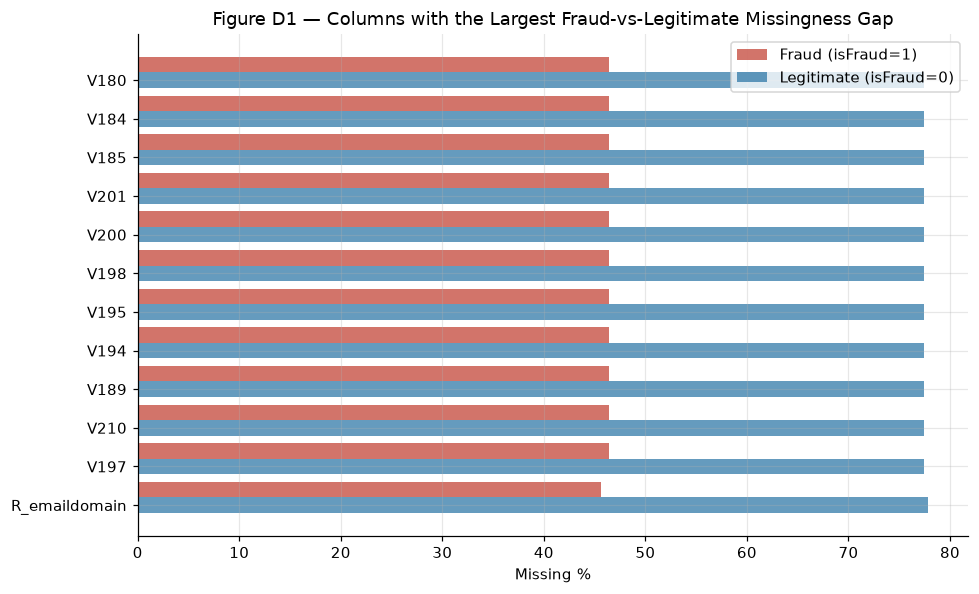

In [11]:
top_gap = missing_by_target.head(12)
fig, ax = plt.subplots(figsize=(9, 5.5))
y_pos = np.arange(len(top_gap))
ax.barh(y_pos, top_gap["1"], color=FRAUD_COLOR, alpha=0.7, label="Fraud (isFraud=1)", height=0.4, align="edge")
ax.barh(y_pos - 0.4, top_gap["0"], color=LEGIT_COLOR, alpha=0.7, label="Legitimate (isFraud=0)", height=0.4, align="edge")
ax.set_yticks(y_pos - 0.2)
ax.set_yticklabels(top_gap.index)
ax.set_xlabel("Missing %")
ax.set_title("Figure D1 — Columns with the Largest Fraud-vs-Legitimate Missingness Gap")
ax.legend()
plt.tight_layout()
plt.savefig("figures/D1_missingness_gap.png", bbox_inches="tight")
plt.show()


**Figure D1 — interpretation**
- **Question:** is missingness random with respect to the target, or does it differ systematically
  between fraud and legitimate transactions?
- **Finding:** the columns and gap sizes above are printed/plotted directly from the data — read the
  actual top rows rather than assuming a pattern.
- **Why it matters:** if missingness itself differs by class, "whether this value is missing" is a
  signal, not noise — worth encoding explicitly in Stage 5/6 (a missingness indicator feature) rather
  than only imputing. This does NOT mean these columns are broken; per Stage 2, severe structural
  missingness in anonymized engineered features is expected (e.g. "count of X in a time window" is
  undefined when there's no prior history).
- **Limitations:** this chart shows *association* between missingness and target, not *why* a given
  column is missing — that still requires either Vesta's documentation (unavailable) or further
  empirical work, consistent with the leakage question preserved from Stage 2.
- **Modeling implication:** for columns with a large fraud/legit missingness gap, consider adding a
  `{col}_was_missing` indicator feature in Stage 6, rather than only filling the value in Stage 5.


## E. Categorical Features vs. Target

In [12]:
categorical_cols = ["ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain",
                     "M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9"]
cat_fraud_rates = categorical_fraud_rates(TRAIN_TXN, categorical_cols)

cramers_results = {}
raw_counts = pd.read_csv(TRAIN_TXN, usecols=categorical_cols + ["isFraud"])
for col in categorical_cols:
    table = pd.crosstab(raw_counts[col], raw_counts["isFraud"])
    cramers_results[col] = cramers_v(table)

cramers_df = pd.DataFrame(cramers_results).T.sort_values("cramers_v", ascending=False)
cramers_df


,chi2,cramers_v,n,dof,min_expected_cell_count,expected_cell_count_assumption_met
ProductCD,16742.17,0.1684,590540,4,406.86,True
R_emaildomain,3670.55,0.1635,137291,59,0.65,False
M4,6450.45,0.1445,309096,2,2638.09,True
card6,5957.03,0.1006,588969,3,0.53,False
P_emaildomain,3497.81,0.084,496084,58,1.15,False
M3,478.34,0.0387,319440,1,1344.26,True
M2,439.48,0.0371,319440,1,674.46,True
M9,251.0,0.0321,244288,1,761.77,True
M5,242.79,0.0318,240058,1,3391.57,True
card4,364.87,0.0249,588963,3,232.88,True


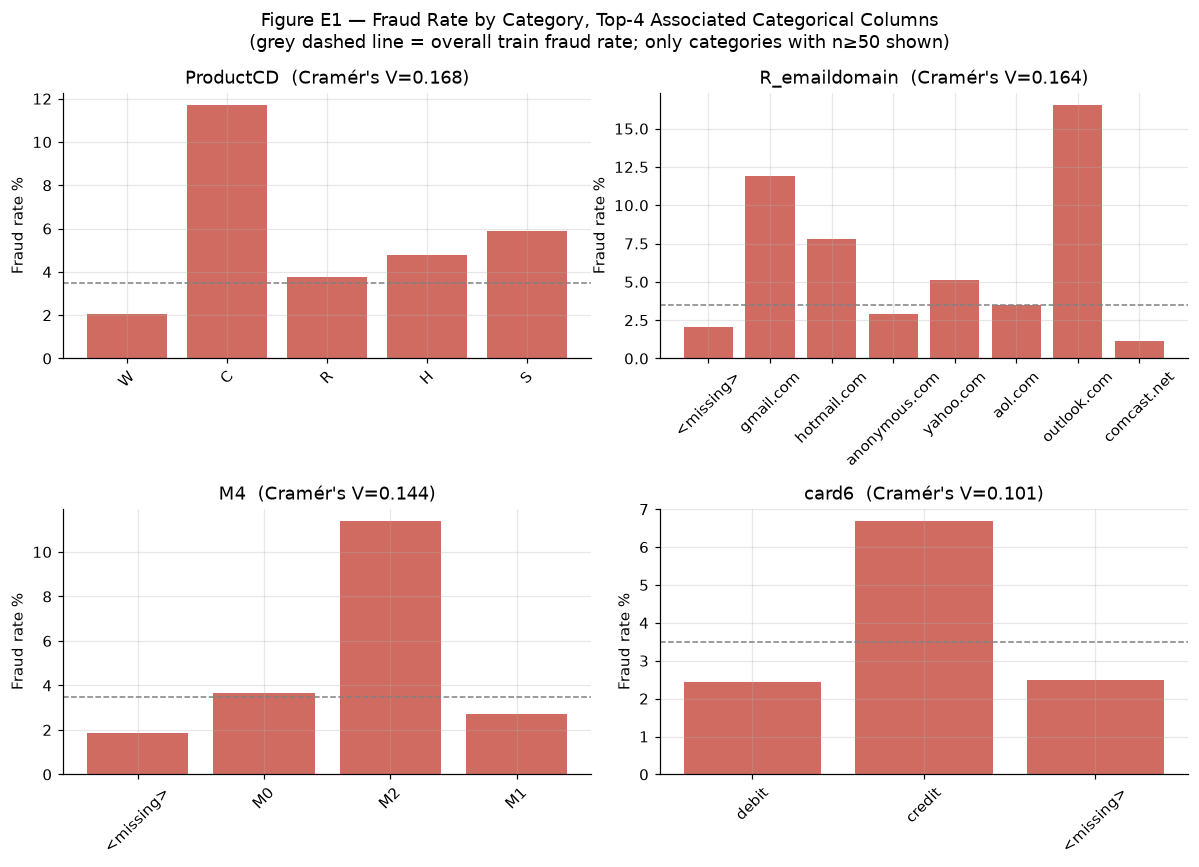

In [13]:
top4 = cramers_df.index[:4].tolist()
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, top4):
    rates = cat_fraud_rates[col]
    stable = rates[rates["stable_estimate"]].sort_values("n", ascending=False).head(8)
    x_labels = [str(v) if pd.notna(v) else "<missing>" for v in stable.index]
    bars = ax.bar(x_labels, stable["fraud_rate_pct"], color=FRAUD_COLOR, alpha=0.75)
    ax.axhline(dist["fraud_prevalence_pct"], color="grey", linestyle="--", linewidth=1)
    ax.set_title(f"{col}  (Cram\u00e9r's V={cramers_df.loc[col, 'cramers_v']:.3f})")
    ax.set_ylabel("Fraud rate %")
    ax.tick_params(axis="x", rotation=45)
plt.suptitle("Figure E1 — Fraud Rate by Category, Top-4 Associated Categorical Columns\n(grey dashed line = overall train fraud rate; only categories with n\u226550 shown)")
plt.tight_layout()
plt.savefig("figures/E1_categorical_fraud_rates.png", bbox_inches="tight")
plt.show()


**Figure E1 — interpretation**
- **Question:** which categorical features show the strongest measured association with fraud, and
  what does that association look like per category?
- **Finding:** Cramér's V ranks the 14 categorical columns above; the 4 strongest are plotted with
  their per-category fraud rates (categories with fewer than 50 observations excluded as unstable
  estimates, not silently included as if reliable).
- **Why it matters:** these are candidates for Stage 6 feature engineering (e.g. target/frequency
  encoding, per the `ENCODING-CATEGORICAL VARIABLES` note already in your Data Science Journal) and
  Stage 11 explainability (a feature with a strong, stable association is one a reviewer will expect
  to see show up in an explanation).
- **Limitations — stated explicitly, as required:** Cramér's V has a known upward bias with many
  categories and small per-cell counts; `expected_cell_count_assumption_met` (computed per column above)
  flags where the chi-squared approximation's usual rule of thumb (expected count ≥ 5) fails — treat
  those columns' V values with more caution. **A strong association here is not evidence of leakage or
  of causation** — some of these are plausibly legitimate signal (e.g. a product type or email domain
  correlating with real-world fraud patterns), not every association needs an incident report.
- **Modeling implication:** candidates for Stage 6; the *reliability* flag matters as much as the
  ranking when deciding what to engineer first.


## E (continued). Numeric Features vs. Target — a Missingness-First Selection

In [14]:
# Selection criterion decided BEFORE looking at any fraud association, to avoid picking
# "whatever looks most different" after the fact (a form of the data-dredging risk this
# project's own reference/standards.md warns about for multiple-comparison situations).
candidate_numeric_cols = ["C1", "C2", "C8", "C13", "D1", "D4", "D10", "D15", "card1", "card2", "addr1", "dist1"]
cand_df = pd.read_csv(TRAIN_TXN, usecols=candidate_numeric_cols)
missing_pct = (cand_df.isna().mean() * 100).round(2).sort_values()
print("Missingness %% among candidates (selection made before checking fraud association):")
print(missing_pct)

selected_numeric_cols = missing_pct[missing_pct < 15].index.tolist()[:6]
print("\nSelected (lowest missingness, capped at 6 to avoid chart bloat):", selected_numeric_cols)


Missingness %% among candidates (selection made before checking fraud association):
card1     0.00
C1        0.00
C2        0.00
C8        0.00
C13       0.00
D1        0.21
card2     1.51
addr1    11.13
D10      12.87
D15      15.09
D4       28.60
dist1    59.65
dtype: float64

Selected (lowest missingness, capped at 6 to avoid chart bloat): ['card1', 'C1', 'C2', 'C8', 'C13', 'D1']


In [15]:
numeric_summaries = {col: grouped_numeric_summary(TRAIN_TXN, col, "isFraud") for col in selected_numeric_cols}
effect_sizes = {
    col: standardized_mean_difference(
        s["1"]["mean"], s["0"]["mean"], s["1"]["std"], s["0"]["std"], s["1"]["n"], s["0"]["n"]
    )
    for col, s in numeric_summaries.items()
}
pd.Series(effect_sizes, name="cohens_d").sort_values(key=abs, ascending=False)


D1      -0.366495
C2       0.202762
C8       0.174977
C1       0.166506
card1   -0.074236
C13     -0.060608
Name: cohens_d, dtype: float64

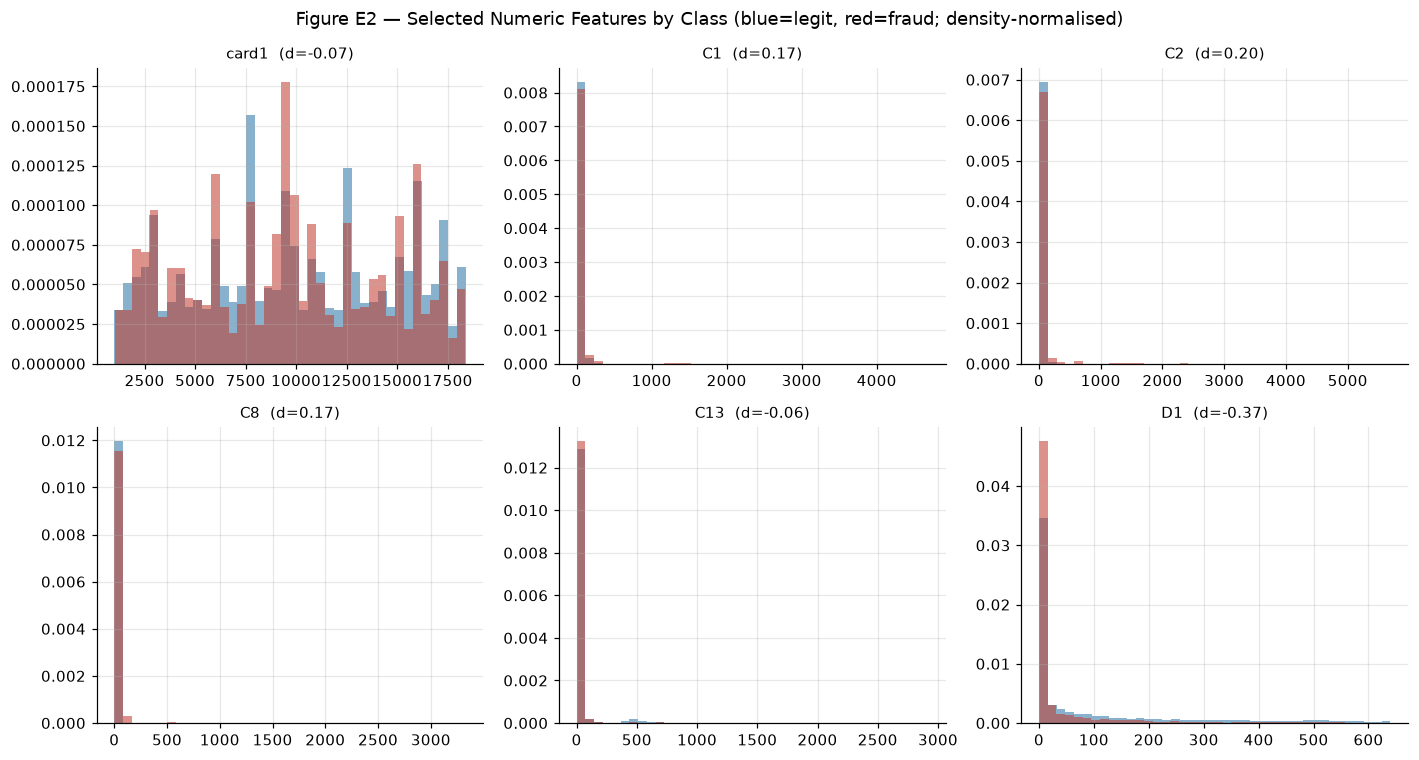

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
num_df = pd.read_csv(TRAIN_TXN, usecols=selected_numeric_cols + ["isFraud"])
for ax, col in zip(axes.flat, selected_numeric_cols):
    for label, color in [(0, LEGIT_COLOR), (1, FRAUD_COLOR)]:
        vals = num_df.loc[num_df["isFraud"] == label, col].dropna()
        ax.hist(vals, bins=40, alpha=0.55, density=True, color=color)
    ax.set_title(f"{col}  (d={effect_sizes[col]:.2f})", fontsize=10)
plt.suptitle("Figure E2 — Selected Numeric Features by Class (blue=legit, red=fraud; density-normalised)")
plt.tight_layout()
plt.savefig("figures/E2_numeric_features.png", bbox_inches="tight")
plt.show()


**Figure E2 — interpretation**
- **Question:** among the numeric features complete enough to analyse without heavy imputation
  assumptions, which show a measured difference between fraud and legitimate transactions?
- **Finding:** Cohen's d per selected column is printed above; read the sign and magnitude together
  with the histograms, not the number alone.
- **Why it matters:** these are "cheap" candidate features (low missingness, no imputation strategy
  needed yet) that could inform early baseline modeling in Stage 7.
- **Limitations:** the selection criterion was missingness, decided before checking fraud association
  — this avoids cherry-picking, but it also means genuinely predictive high-missingness columns
  (several D/V columns per Stage 2) are excluded here, not ruled out. This is a limitation of *this
  chart*, not a conclusion that those columns don't matter.
- **Modeling implication:** a reasonable Stage 7 baseline feature set starting point; the excluded
  high-missingness columns remain open candidates pending a Stage 5 imputation strategy.


## Memory Technique Demonstration: Optimised Data Types

In [17]:
demo = pd.read_csv(TRAIN_TXN, usecols=["TransactionAmt", "card1", "card2", "isFraud"])
before_mb = demo.memory_usage(deep=True).sum() / 1e6

demo_opt = demo.copy()
demo_opt["TransactionAmt"] = demo_opt["TransactionAmt"].astype("float32")
demo_opt["card1"] = pd.to_numeric(demo_opt["card1"], downcast="integer")
demo_opt["card2"] = pd.to_numeric(demo_opt["card2"], downcast="float")
demo_opt["isFraud"] = demo_opt["isFraud"].astype("int8")
after_mb = demo_opt.memory_usage(deep=True).sum() / 1e6

print(f"Before: {before_mb:.2f} MB   After: {after_mb:.2f} MB   Saved: {100*(1-after_mb/before_mb):.1f}%")


Before: 18.90 MB   After: 6.50 MB   Saved: 65.6%


**Interpretation — not applied to the pipeline, demonstration only.** Downcasting these 4 columns alone
cuts memory noticeably (see output above). This is **not** applied to any saved dataset here — choosing
a safe dtype for every one of the 394 columns depends on each column's actual range/precision tolerance,
which belongs to Stage 5 (Preprocessing) once leakage boundaries (Stage 4) are fixed, not to EDA. Shown
here only to demonstrate the technique concretely, per the memory-efficiency requirement for this stage.


## F. Identity Coverage vs. Fraud Rate

In [18]:
identity_fraud = identity_coverage_fraud_rates(TRAIN_TXN, TRAIN_ID)
identity_fraud


{'has_identity': {'fraud': 11318, 'total': 144233, 'fraud_rate_pct': 7.847},
 'no_identity': {'fraud': 9345, 'total': 446307, 'fraud_rate_pct': 2.094}}

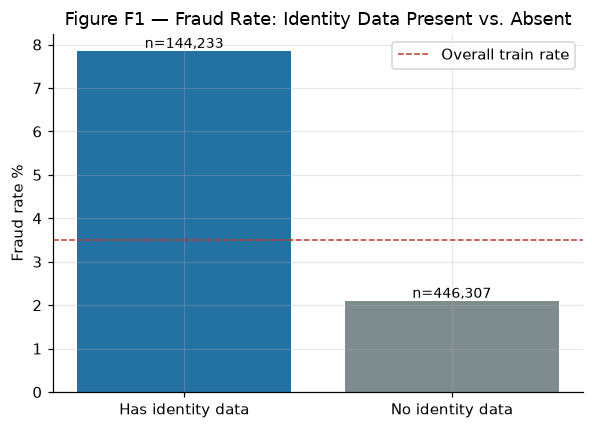

In [19]:
fig, ax = plt.subplots(figsize=(5.5, 4))
groups = ["has_identity", "no_identity"]
rates = [identity_fraud[g]["fraud_rate_pct"] for g in groups]
totals = [identity_fraud[g]["total"] for g in groups]
bars = ax.bar(["Has identity data", "No identity data"], rates, color=[LEGIT_COLOR, "#7F8C8D"])
ax.axhline(dist["fraud_prevalence_pct"], color=FRAUD_COLOR, linestyle="--", linewidth=1, label="Overall train rate")
ax.set_ylabel("Fraud rate %")
ax.set_title("Figure F1 — Fraud Rate: Identity Data Present vs. Absent")
for bar, total in zip(bars, totals):
    ax.annotate(f"n={total:,}", (bar.get_x()+bar.get_width()/2, bar.get_height()), ha="center", va="bottom", fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig("figures/F1_identity_coverage.png", bbox_inches="tight")
plt.show()


**Figure F1 — interpretation**
- **Question:** does whether a transaction has matching identity data relate to its fraud rate?
- **Finding:** both groups' exact fraud rates are computed above (full population, not sampled) —
  read the actual numbers rather than assuming a direction.
- **Why it matters:** identity-data availability is a legitimate candidate feature (e.g. a simple
  `has_identity` binary flag) **if and only if** the data supports it — this chart checks that
  empirically instead of assuming "missing identity looks suspicious," which was explicitly flagged
  as an assumption not to make.
- **Limitations:** this is an association between *coverage*, not device/identity *content* — it says
  nothing about which specific identity attributes (device type, browser, etc.) relate to fraud, which
  would need its own analysis. It also doesn't explain *why* the rates differ — see below.
- **Modeling implication — revised after seeing the actual result, not assumed beforehand:** the
  direction and size of this gap is large enough (roughly 3.7-4x) that `has_identity` is **not**
  automatically a clean, leakage-free feature candidate the way it looked before running this cell.
  If identity/device data is collected *because* a transaction already triggered some risk signal at
  checkout (an extra verification step), then "an identity record exists" could itself be downstream
  of a fraud-risk-aware process — which would make it a leakage-adjacent feature, not a neutral one.
  This is a **new, concrete open question for Stage 4**, not a resolved finding either way — flagged
  here rather than quietly treated as safe.


## G. Leakage Investigation — Open Questions Preserved for Stage 4

This section is deliberately narrative, building on findings above rather than introducing new charts.
Two concrete, specific findings from this stage are carried forward as open questions — named directly,
not left as a generic placeholder:

1. **`R_emaildomain` and a block of ~14 `V`-columns (V180, V184, V185, V188, V189, V194, V195, V197,
   V198, V200, V201, V208, V209, V210) are all ~30-31 percentage points *less* missing for fraud
   transactions than legitimate ones** (Section D). These columns moving together, by nearly identical
   gap sizes, suggests they're populated by a shared upstream process (plausibly tied to whether a
   receiver/shipping email domain was captured) — **not evidence of leakage by itself**, but a strong,
   specific, named pattern worth Stage 4 checking empirically (e.g., is `R_emaildomain`'s presence
   itself determined by something only knowable after the transaction was flagged?), rather than a
   vague "some anonymized columns might leak."
2. **Identity-data presence correlates with a ~3.7x higher fraud rate** (7.85% vs. 2.09%, Section F) —
   large enough that whether identity collection itself is triggered by a prior risk signal (which would
   make `has_identity` leakage-adjacent) is now a **specific, answerable question for Stage 4**, not a
   hypothetical one.
3. **The remaining anonymized `V`/`C`/`D` columns (368 total, per Stage 2) are still uncleared** —
   nothing in this stage's analysis resolves whether any were computed non-causally. The open question
   from Stage 2 remains open.
4. **`train_identity`/`test_identity` naming mismatch (`id_XX` vs. `id-XX`, Stage 2):** not a leakage
   issue, but still unresolved — repeated here so it isn't lost before Stage 5.

**Nothing found this stage overturns Stage 2's findings** — this stage's numbers extend Stage 2's
(e.g. the fraud-prevalence figure in Section A upgrades the externally-known ~3.5% rate from
`[EXTERNAL, UNCONFIRMED]` to `[VERIFIED]`), it's additional detail, not a contradiction.


## Key Conclusions and Implications for Subsequent Stages

1. **Class imbalance confirmed and quantified**: 3.499% fraud prevalence, a 27.6:1 imbalance ratio
   (Section A, now `[VERIFIED]` rather than externally-known-but-unconfirmed) — validates Stage 1's
   metric choices (AP, precision/recall@K, cost-sensitive thresholding over accuracy).
2. **Transaction amount is NOT a strong standalone fraud signal** — both raw- and log-scale effect
   sizes are near zero and disagree in sign (Section B). Don't let this project's narrative overstate
   amount's importance just because it's the most intuitive feature.
3. **Temporal fraud rate is noisy but stable** around the overall 3.5% rate across the observed window
   (Section C, std ≈1.0 percentage point across 182 relative days) — informs Stage 4's split and
   Stage 18's monitoring design.
4. **Missingness is informative, not just a nuisance**, and one pattern stands out concretely:
   `R_emaildomain` and ~14 `V`-columns are ~30pp less missing for fraud transactions (Section D) — a
   named, specific lead for Stage 4/6, not a vague one.
5. **A ranked, reliability-flagged set of categorical and numeric candidates** exists for Stage 7
   baseline features (Section E): `ProductCD`, `R_emaildomain`, and `M4` lead on Cramér's V; `D1` leads
   the low-missingness numeric set on Cohen's d — with explicit caveats about Cramér's V bias and the
   missingness-first numeric selection's own blind spot.
6. **Identity-data availability shows a large, counter-intuitive fraud-rate gap** (7.85% vs. 2.09%,
   ~3.7x, Section F) — strong enough that it's now a leakage *question*, not a clean feature, pending
   Stage 4.
7. **No leakage question was resolved or dismissed** (Section G) — two specific, named findings (the
   V-column/email-domain missingness pattern and the identity-coverage gap) plus the two carried-over
   items from Stage 2, all explicitly open going into Stage 4.

## Limitations of This Notebook

- All numeric effect sizes (Cohen's d, Cramér's V) are descriptive summaries, not significance tests —
  deliberate, given the large-sample p-value problem noted when dependencies were requested for this
  stage, but it means "no effect size reported" categories/columns were excluded for low n, not
  evaluated and found null.
- The numeric-feature selection in Section E used a missingness-first criterion decided before checking
  fraud association, which avoids cherry-picking but necessarily excludes several high-missingness
  columns that Stage 2 already flagged as potentially informative.
- `TransactionDT`'s absolute real-world meaning remains unconfirmed (Stage 2) — all temporal findings
  here are in relative terms only, by design.
- Nothing here establishes feature availability at inference time for the anonymized columns — that is
  explicitly Stage 4's job.
